# PCA portfolios: 90-day walk-forward experiment

**Question.** Does using principal component analysis (PCA) to estimate how stocks move together improve the portfolios we build?

This notebook compares three ways of investing in the same eligible stocks: PCA minimum variance, sample-covariance minimum variance, and equal weight. **Minimum variance** means choosing the mix with the lowest estimated portfolio variance. All three methods use the same historical information and trading costs.

The candidate universe is the **January 1, 2020 S&P 500 roster**. It is held fixed throughout the experiment, so companies added to the index later do not enter this universe. The roster has 505 securities because some companies are represented by multiple share classes. [Historical roster](https://github.com/shardul0701/SP500-Survivorship-bias-data-2004-2026/blob/main/src/sp500_ticker_history/sp500-ticker-changes-2020.yaml)

At each entry date, the code trains on 252 daily returns ending before entry, chooses the weights, buys at the entry close, and measures performance over the next 90 calendar days. It repeats this process on new dates, moving weekend or holiday boundaries to the next available trading day. The final partial period is left out.

## 1. Imports, stock list, and settings

The imports load the packages for tables, math, optimization, PCA, and charts. Uncomment the install line if your environment is missing a package.

The stock list records the historical symbols from the January 1 snapshot. The next line converts the class-share separator to Yahoo Finance's format, for example `BRK.B` becomes `BRK-B`. The settings below the list control four things:

- **Price dates.** The download starts in 2020 to provide training history. The first scheduled investment is in 2022.
- **Training and holding.** `TRAIN_DAYS` counts daily returns used to fit each model. `HOLD_CALENDAR_DAYS` counts calendar days between scheduled trades.
- **Risk and costs.** The PCA model keeps enough components to explain at least 80% of the training variance. Each stock can get up to 10% of the portfolio. A cost of 10 basis points means 0.10% of the dollars traded on each side.
- **Data source.** Leave `CSV_PATH` as `None` to request Yahoo Finance data. Set it to a saved adjusted-close file for historical ticker and delisting coverage supplied by another provider.

In [1]:
# Uncomment if needed:
# %pip install numpy pandas matplotlib scipy scikit-learn yfinance

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.decomposition import PCA
from IPython.display import display

# a batch of 20 arbitrarily chosen stocks 
TICKERS = [
    "AAPL", "MSFT", "AMZN", "GOOGL", "JPM", "BAC", "JNJ", "UNH",
    "PG", "KO", "WMT", "HD", "XOM", "CVX", "CAT", "HON",
    "NEE", "DUK", "DIS", "VZ",
]

# Dates and rebalance settings
DOWNLOAD_START = "2020-01-01"
DOWNLOAD_END = "2026-01-01"  # Exclusive.
TEST_START = "2022-01-03"
TRAIN_DAYS = 252
HOLD_CALENDAR_DAYS = 90

# Portfolio settings
VARIANCE_TARGET = 0.80
MAX_WEIGHT = 0.10
COST_BPS = 10  # Per dollar bought OR sold.
INITIAL_CAPITAL = 10_000.0
CSV_PATH = None  # Optional daily adjusted-close CSV: date index, ticker columns.

# Catch invalid settings before downloading prices.
assert TRAIN_DAYS >= 2 and HOLD_CALENDAR_DAYS > 0
assert 0 < VARIANCE_TARGET <= 1 and 0 < MAX_WEIGHT <= 1
assert 0 <= COST_BPS < 10_000
assert len(TICKERS) == len(set(TICKERS))
assert len(TICKERS) * MAX_WEIGHT >= 1


## 2. Load daily adjusted prices

The cell builds a table with **one trading day per row** and **one ticker per column**. It uses adjusted closes so the return calculation reflects splits and dividend adjustments in the price series.

The data comes from Yahoo Finance or an optional local CSV. A CSV should have dates in its first column, adjusted prices in the ticker columns, and a `SPY` column for the benchmark. Use the notebook's historical ticker labels and class-share format. Blank values represent missing prices.

The coverage table reports how many prices each ticker has. Yahoo can omit delisted or renamed symbols, and a historical symbol may have been reused. A price file with verified security identities and corporate-action coverage is needed for a full-roster historical test. Eligibility is decided from the prices available **before each entry**. If a stock with a positive weight is missing a price during the holding period, the backtest stops and reports the gap so its performance is not guessed.

In [2]:
# Load prices from one source and keep the original CSV available for SPY.
if CSV_PATH is not None:
    csv_prices = pd.read_csv(CSV_PATH, index_col=0, parse_dates=True)
    prices = csv_prices.copy()
else:
    try:
        import yfinance as yf
    except ImportError as exc:
        raise ImportError("Install yfinance using the commented %pip line, or set CSV_PATH.") from exc
    # An adjusted Close can be used directly to calculate daily returns.
    raw = yf.download(TICKERS, start=DOWNLOAD_START, end=DOWNLOAD_END,
                      interval="1d", auto_adjust=True, progress=False)
    if raw is None or raw.empty:
        raise RuntimeError("No prices downloaded. Check the connection and ticker symbols.")
    prices = raw["Close"].copy()
    if isinstance(prices, pd.Series):
        prices = prices.to_frame(TICKERS[0])

# Sort dates, line up the ticker columns, and keep the requested period.
prices.index = pd.DatetimeIndex(pd.to_datetime(prices.index)).tz_localize(None)
prices = prices.sort_index().reindex(columns=TICKERS).astype(float)

start = pd.Timestamp(DOWNLOAD_START)
end = pd.Timestamp(DOWNLOAD_END)
in_date_range = (prices.index >= start) & (prices.index < end)
prices = prices.loc[in_date_range]
if prices.empty or prices.index.has_duplicates:
    raise ValueError("Prices must have a nonempty, unique daily date index.")
observed_prices = prices.to_numpy()[prices.notna().to_numpy()]
if not np.isfinite(observed_prices).all():
    raise ValueError("Found infinite prices.")
if (prices <= 0).any().any():
    raise ValueError("Adjusted prices must be positive.")
if prices.isna().all(axis=1).any():
    raise ValueError("A supplied date has no prices; inspect the data instead of silently dropping it.")

# Keep missing values in the price table. Each training window checks its own coverage.
price_counts = pd.DataFrame({"observed_prices": prices.count(), "missing_prices": prices.isna().sum()})
covered_tickers = price_counts["observed_prices"] > 0
print(f"Tickers with at least one price: {covered_tickers.sum()} of {len(TICKERS)}")
if not covered_tickers.all():
    print("No prices returned for:", ", ".join(price_counts.index[~covered_tickers]))
display(price_counts)
print(f"Dates: {prices.index.min().date()} through {prices.index.max().date()}")
print("No full-period stock filtering has been applied.")


Tickers with at least one price: 20 of 20


,observed_prices,missing_prices
Ticker,,
AAPL,1508,0
MSFT,1508,0
AMZN,1508,0
GOOGL,1508,0
JPM,1508,0
BAC,1508,0
JNJ,1508,0
UNH,1508,0
PG,1508,0


Dates: 2020-01-02 through 2025-12-31
No full-period stock filtering has been applied.


## 3. Construct the portfolio weights

Each time this section runs, it receives only prices from before the entry date. It takes the last **253 closing prices** to calculate **252 daily percentage returns**. Each ticker needs a complete training window and returns that vary. All three strategies use the resulting set of eligible stocks.

1. **Sample covariance.** Calculate a matrix from the historical returns. The diagonal contains each stock's variance. The other cells describe how pairs of stocks move together.
2. **PCA covariance.** Fit PCA to the same daily percentage returns. Each component describes a pattern of movement across stocks. Keep the first components until their cumulative explained variance reaches 80%. Rebuild the covariance using the retained patterns, then add back the leftover individual variance on the diagonal. Both covariance estimates receive the same tiny diagonal adjustment for numerical stability.
3. **Minimum-variance weights.** Solve the same problem separately with each covariance estimate. The objective is `weights.T @ covariance @ weights`, the portfolio's estimated variance. The optimizer starts at equal weights and uses the gradient to search for a lower-variance mix. The final weights must total 100%, with each stock between 0% and 10%.
4. **Equal weights.** Divide the money evenly across the eligible stocks. For example, 400 eligible stocks get 0.25% each.

The function returns a weight table, plus information about the dates, excluded tickers, and PCA components used for that decision.

In [3]:
def minimum_variance_weights(covariance, max_weight):
    """Find the lowest-variance weights that sum to one and respect the stock cap."""
    n = covariance.shape[0]
    if n * max_weight < 1 - 1e-10:
        raise ValueError("Too few eligible stocks for the weight cap.")
    # Divide by the mean stock variance to make the numbers easier to optimize.
    scale = np.trace(covariance) / n
    if not np.isfinite(scale) or scale <= 0:
        raise ValueError("Invalid covariance scale.")
    scaled_covariance = covariance / scale

    # Minimize portfolio variance with weights that add up to 100%.
    equal_weights = np.full(n, 1 / n)
    weight_bounds = [(0.0, max_weight)] * n
    weight_constraint = {"type": "eq", "fun": lambda weights: weights.sum() - 1,
                         "jac": lambda weights: np.ones(n)}
    # The objective is portfolio variance. Its gradient gives the slope for each weight.
    result = minimize(
        fun=lambda weights: weights @ scaled_covariance @ weights,
        jac=lambda weights: 2 * scaled_covariance @ weights,
        x0=equal_weights,
        method="SLSQP",
        bounds=weight_bounds,
        constraints=[weight_constraint],
        options={"ftol": 1e-10, "maxiter": 1000},
    )
    if not result.success:
        raise RuntimeError(f"Optimization failed: {result.message}")
    weights = result.x
    bad_total = abs(weights.sum() - 1) > 1e-7
    outside_bounds = weights.min() < -1e-8 or weights.max() > max_weight + 1e-7
    if bad_total or outside_bounds:
        raise RuntimeError("Optimizer returned invalid weights.")

    weights = np.maximum(weights, 0)
    return weights / weights.sum()


def fit_portfolios(history, train_days, variance_target, max_weight):
    """Use pre-entry prices to return three sets of weights and a training summary."""
    # Use the training window and keep stocks with complete prices.
    # One extra closing price is needed to calculate the first daily return.
    window = history.tail(train_days + 1)
    if len(window) != train_days + 1:
        raise ValueError("Not enough training history. Move TEST_START later.")
    eligible = window.columns[window.notna().all()]
    # Calculate ordinary daily percentage returns. The first price has no prior day.
    returns = window[eligible].pct_change(fill_method=None).iloc[1:]
    has_variation = returns.var(ddof=1) > 1e-12
    returns = returns.loc[:, has_variation]

    stock_count = returns.shape[1]
    if stock_count * max_weight < 1 - 1e-10:
        raise ValueError("Too few complete, nonconstant stocks in this training window.")

    sample_cov = returns.cov().to_numpy()
    # Keep enough components to reach the variance target.
    pca = PCA(svd_solver="full").fit(returns)
    cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
    target_position = np.searchsorted(cumulative_variance, variance_target)
    component_count = min(int(target_position) + 1, len(cumulative_variance))

    # Rebuild the covariance from the kept components and add leftover stock variance.
    directions = pca.components_[:component_count].T
    component_variance = pca.explained_variance_[:component_count]
    # Weight each component direction by its variance, then combine the directions.
    common_cov = (directions * component_variance) @ directions.T
    leftover_variance = np.maximum(np.diag(sample_cov - common_cov), 0)
    pca_cov = common_cov + np.diag(leftover_variance)

    # Add the same small diagonal adjustment to both covariance estimates.
    ridge = 1e-8 * np.trace(sample_cov) / stock_count
    diagonal_adjustment = ridge * np.eye(stock_count)
    pca_weights = minimum_variance_weights(pca_cov + diagonal_adjustment, max_weight)
    sample_weights = minimum_variance_weights(sample_cov + diagonal_adjustment, max_weight)
    # Equal weight is the baseline and skips the covariance optimizer.
    equal_weights = np.full(stock_count, 1 / stock_count)

    weights = pd.DataFrame({"PCA": pca_weights, "Sample covariance": sample_weights,
                            "Equal weight": equal_weights}, index=returns.columns)
    info = {
        "train_start": window.index[0],
        "train_end": window.index[-1],
        "train_returns": len(returns),
        "stocks": stock_count,
        "components": component_count,
        "explained_variance": cumulative_variance[component_count - 1],
        "excluded": ", ".join(history.columns.difference(returns.columns)),
    }
    return weights, info


## 4. Build the trading schedule and measure each holding period

**Schedule.** Start at `TEST_START` and place a boundary every 90 calendar days. If the market is closed on a boundary, use the next available trading day. Two consecutive boundaries define a holding period.

**Value of a holding.** Divide each stock's daily adjusted price by its entry price. This gives the value of one dollar invested in that stock at entry. Multiply each stock's price ratio by its starting weight and sum across stocks to get the portfolio's gross value on each date. The code uses the same starting shares throughout the interval, so weights drift as prices move.

**Fees and performance.** If the fee rate is `c`, invest `capital / (1 + c)` at entry and receive `sale proceeds * (1 - c)` at exit. The code records gross return, net return after both fees, annualized volatility from daily market returns, and the largest drop from a running peak within the interval.

**Timing.** For each period, the weight calculation receives dates strictly earlier than entry. The entry-through-exit prices are passed to the performance calculation after weights are set.

In [4]:
def make_boundaries(index, test_start, hold_days):
    """Map scheduled calendar dates to the next available trading dates."""
    scheduled = pd.date_range(pd.Timestamp(test_start), index[-1], freq=f"{hold_days}D")

    # If the scheduled date is closed, use the next trading day.
    positions = index.searchsorted(scheduled)
    valid = positions < len(index)
    schedule = pd.DataFrame({"scheduled": scheduled[valid], "execution": index[positions[valid]]})
    # Two scheduled boundaries can map to the same day if the market is closed.
    schedule = schedule.drop_duplicates("execution")
    if len(schedule) < 2:
        raise ValueError("Not enough data for one complete holding interval.")
    return schedule.reset_index(drop=True)


def evaluate_hold(held_prices, weights, cost_bps):
    """Measure buy-and-hold return, volatility, and drawdown for one interval."""
    if len(held_prices) < 2 or held_prices.isna().any().any():
        raise ValueError("Missing held prices or an empty interval. Inspect the data.")
    # Convert each price path to the growth of one dollar invested at entry.
    relative_prices = held_prices / held_prices.iloc[0]
    gross_value = relative_prices.to_numpy() @ weights.to_numpy()
    market_returns = gross_value[1:] / gross_value[:-1] - 1

    # Include the cost of buying at entry and selling at exit.
    cost = cost_bps / 10_000
    net_value = gross_value / (1 + cost)
    net_value[-1] *= 1 - cost  # Liquidate at the final close.
    # Include the starting cash so the first fee also counts toward drawdown.
    with_initial_cash = np.r_[1.0, net_value]
    running_peak = np.maximum.accumulate(with_initial_cash)
    drawdowns = with_initial_cash / running_peak - 1
    return {
        "gross_return": gross_value[-1] - 1,
        "net_return": net_value[-1] - 1,
        "annualized_volatility": np.std(market_returns, ddof=1) * np.sqrt(252),
        "interval_max_drawdown": drawdowns.min(),
    }


def run_backtest(price_data, test_start, train_days, hold_days,
                 variance_target, max_weight, cost_bps):
    """Refit before each entry and return the results, audit table, and allocations."""
    schedule = make_boundaries(price_data.index, test_start, hold_days)
    records = []
    audits = []
    allocations = {}

    for interval in range(len(schedule) - 1):
        entry = schedule.loc[interval, "execution"]
        exit_date = schedule.loc[interval + 1, "execution"]
        # Strictly earlier prices: entry-day returns cannot affect weights.
        history = price_data.loc[price_data.index < entry]
        weights, info = fit_portfolios(history, train_days, variance_target, max_weight)
        held = price_data.loc[entry:exit_date, weights.index]
        # The equal-weight comparison holds every eligible stock, so every price is needed.
        if held.isna().any().any():
            missing = held.columns[held.isna().any()].tolist()
            raise ValueError(f"Missing holding-period prices for {missing}, starting {entry.date()}. "
                             "Supply adjusted prices with corporate-action coverage in CSV_PATH.")
        assert info["train_end"] < entry < exit_date
        allocations[entry] = weights
        audits.append({
            "entry": entry, "exit": exit_date,
            "calendar_days": (exit_date - entry).days,
            "holding_returns": len(held) - 1,
            **info,
        })
        # Reuse the same price path, dates, and costs for each set of weights.
        for strategy in weights.columns:
            metrics = evaluate_hold(held, weights[strategy], cost_bps)
            records.append({"entry": entry, "exit": exit_date, "strategy": strategy, **metrics})

    results = pd.DataFrame(records)
    audit = pd.DataFrame(audits)
    return results, audit, allocations


## 5. Run the historical tests

Call the backtest with the price table and the settings from Section 1. It returns three objects:

- `results` has one row per strategy per holding period, including returns, volatility, and drawdown.
- `audit` has one row per holding period, including the training dates, the number of eligible stocks, the PCA component count, and the excluded ticker symbols.
- `allocations` stores a weight table for each entry date. Look up an entry date to see how the three strategies split their money.

The net-return table arranges the results with one exit date per row and one strategy per column. Use the audit table to see how data coverage changed over time.

In [5]:
results, audit, allocations = run_backtest(prices, TEST_START, TRAIN_DAYS, HOLD_CALENDAR_DAYS,
                                           VARIANCE_TARGET, MAX_WEIGHT, COST_BPS)
display(audit)
# Rearrange the net returns so each strategy gets its own column.
net_returns = results.pivot(index="exit", columns="strategy", values="net_return")
display(net_returns.style.format("{:.2%}"))
print(f"Completed {len(audit)} intervals; incomplete final interval excluded.")


,entry,exit,calendar_days,holding_returns,train_start,train_end,train_returns,stocks,components,explained_variance,excluded
0,2022-01-03,2022-04-04,91,63,2020-12-31,2021-12-31,252,20,8,0.822276,
1,2022-04-04,2022-07-05,92,62,2021-04-05,2022-04-01,252,20,7,0.803063,
2,2022-07-05,2022-09-30,87,62,2021-07-01,2022-07-01,252,20,7,0.825896,
3,2022-09-30,2022-12-29,90,62,2021-09-29,2022-09-29,252,20,7,0.828549,
4,2022-12-29,2023-03-29,90,61,2021-12-28,2022-12-28,252,20,6,0.814530,
5,2023-03-29,2023-06-27,90,61,2022-03-25,2023-03-28,252,20,6,0.817324,
6,2023-06-27,2023-09-25,90,62,2022-06-23,2023-06-26,252,20,6,0.800270,
7,2023-09-25,2023-12-26,92,64,2022-09-21,2023-09-22,252,20,7,0.803751,
8,2023-12-26,2024-03-25,90,61,2022-12-21,2023-12-22,252,20,9,0.824482,
9,2024-03-25,2024-06-21,88,61,2023-03-22,2024-03-22,252,20,9,0.812647,


strategy,Equal weight,PCA,Sample covariance
exit,,,
2022-04-04 00:00:00,0.64%,-0.98%,-0.17%
2022-07-05 00:00:00,-12.16%,-10.31%,-9.67%
2022-09-30 00:00:00,-5.65%,-7.38%,-7.15%
2022-12-29 00:00:00,11.16%,14.78%,15.40%
2023-03-29 00:00:00,-0.76%,-5.71%,-5.96%
2023-06-27 00:00:00,5.47%,1.62%,1.83%
2023-09-25 00:00:00,0.90%,1.89%,1.60%
2023-12-26 00:00:00,6.04%,2.88%,2.81%
2024-03-25 00:00:00,8.11%,6.99%,6.20%


Completed 16 intervals; incomplete final interval excluded.


### S&P 500 benchmark (SPY)

SPY is an ETF that tracks the S&P 500. The code takes its adjusted close from Yahoo Finance or the `SPY` column in the same CSV. SPY is used for comparison only. [SPY fund description](https://www.ssga.com/us/en/individual/etfs/state-street-spdr-sp-500-etf-trust-spy)

For each period, a 100% weight in SPY goes through the same holding calculation as the stock portfolios. Its gross return is `exit price / entry price - 1`. Using the whole daily price path also lets us calculate volatility and drawdown. It uses the same entry dates, exit dates, and trading fees as the other strategies.

In [6]:
BENCHMARK_TICKER = "SPY"
BENCHMARK_LABEL = "S&P 500 proxy (SPY)"

# Get SPY adjusted closes over the dates used in the backtest.
first_entry = audit["entry"].iloc[0]
last_exit = audit["exit"].iloc[-1]
if CSV_PATH is not None:
    if BENCHMARK_TICKER not in csv_prices:
        raise ValueError("Add an adjusted-close SPY column to the price CSV.")
    spy = csv_prices[BENCHMARK_TICKER].copy()
else:
    download_end = last_exit + pd.Timedelta(days=1)  # Yahoo's end date is exclusive.
    spy_data = yf.download(BENCHMARK_TICKER, start=first_entry, end=download_end,
                           auto_adjust=True, progress=False, multi_level_index=False)
    if spy_data is None or spy_data.empty:
        raise RuntimeError("No SPY prices downloaded. Retry before comparing results.")
    spy = spy_data["Close"]

spy.index = pd.DatetimeIndex(pd.to_datetime(spy.index)).tz_localize(None)
# Match SPY to every trading date used by the portfolio backtest.
spy = spy.reindex(prices.loc[first_entry:last_exit].index).astype(float)
if not np.isfinite(spy).all() or (spy <= 0).any():
    raise ValueError("SPY has missing or invalid prices on the backtest dates.")

# Treat SPY as a one-ticker portfolio with the same holding periods and costs.
spy_prices = spy.to_frame(BENCHMARK_TICKER)
spy_weight = pd.Series({BENCHMARK_TICKER: 1.0})
benchmark_records = []
for interval in audit.itertuples(index=False):
    metrics = evaluate_hold(spy_prices.loc[interval.entry:interval.exit], spy_weight, COST_BPS)
    benchmark_records.append({"entry": interval.entry, "exit": interval.exit,
                              "strategy": BENCHMARK_LABEL, **metrics})

benchmark_results = pd.DataFrame(benchmark_records)
comparison_results = pd.concat([results, benchmark_results], ignore_index=True)
comparison_returns = comparison_results.pivot(index="exit", columns="strategy", values="net_return")
assert comparison_returns.index.equals(net_returns.index)
assert comparison_returns.notna().all().all()
display(comparison_returns.style.format("{:.2%}"))


strategy,Equal weight,PCA,S&P 500 proxy (SPY),Sample covariance
exit,,,,
2022-04-04 00:00:00,0.64%,-0.98%,-4.27%,-0.17%
2022-07-05 00:00:00,-12.16%,-10.31%,-16.19%,-9.67%
2022-09-30 00:00:00,-5.65%,-7.38%,-6.29%,-7.15%
2022-12-29 00:00:00,11.16%,14.78%,7.63%,15.40%
2023-03-29 00:00:00,-0.76%,-5.71%,4.86%,-5.96%
2023-06-27 00:00:00,5.47%,1.62%,8.86%,1.83%
2023-09-25 00:00:00,0.90%,1.89%,-0.75%,1.60%
2023-12-26 00:00:00,6.04%,2.88%,10.27%,2.81%
2024-03-25 00:00:00,8.11%,6.99%,9.40%,6.20%


## 6. Compare results

The summary table reports total and annualized net return, average annualized volatility across periods, the worst drop within any one period, and the share of periods with a positive return.

The line chart starts each strategy with the same capital and reinvests the proceeds at every boundary. Each point represents an interval ending value. The bar chart shows each strategy's net return for each interval. The printed comparisons count how often PCA had lower volatility or higher return, and the last allocation table shows the weights from the first entry.

To see what PCA adds, compare it with **sample-covariance minimum variance**. Both strategies solve the same optimization problem, using different estimates of how the stocks move together. Equal weight and SPY provide additional comparisons.

,total_net_return,annualized_net_return,mean_interval_volatility,worst_within_interval_drawdown,positive_interval_fraction
strategy,,,,,
Equal weight,46.14%,10.09%,13.33%,-15.21%,75.00%
PCA,34.93%,7.88%,11.82%,-15.70%,75.00%
S&P 500 proxy (SPY),45.47%,9.96%,16.76%,-19.82%,68.75%
Sample covariance,34.09%,7.71%,11.75%,-15.27%,68.75%


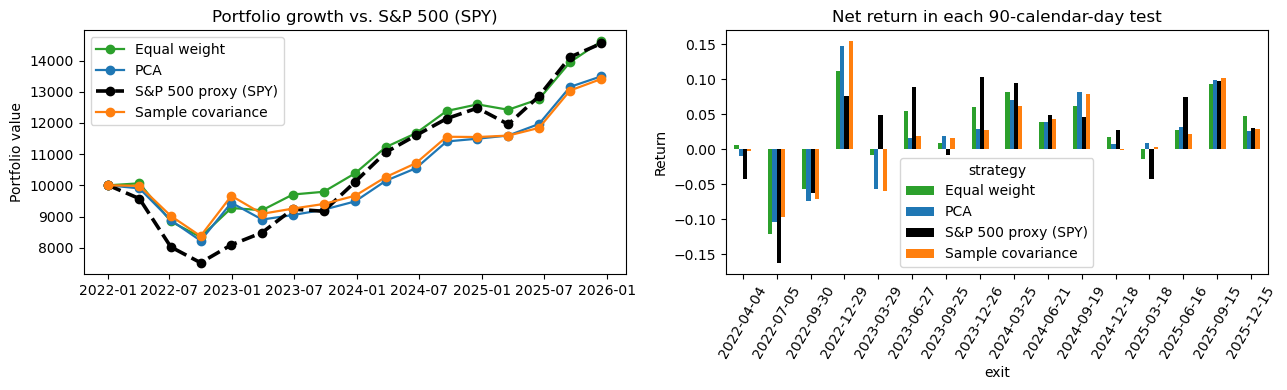

Fraction of intervals in which PCA had:
  lower volatility than equal weight: 93.8%
  lower volatility than sample covariance: 31.2%
  higher net return than equal weight: 50.0%


,PCA,Sample covariance,Equal weight
Ticker,,,
VZ,10.00%,10.00%,5.00%
WMT,10.00%,10.00%,5.00%
PG,10.00%,10.00%,5.00%
JNJ,10.00%,10.00%,5.00%
DUK,10.00%,10.00%,5.00%
JPM,10.00%,10.00%,5.00%
KO,10.00%,10.00%,5.00%
AMZN,10.00%,10.00%,5.00%
MSFT,7.98%,7.41%,5.00%


  higher net return than SPY: 43.8%
  lower volatility than SPY: 100.0%


In [7]:
# Compound each strategy's net returns across the holding periods.
ending_growth = (1 + comparison_returns).cumprod()
start_date = audit.iloc[0]["entry"]
end_date = audit.iloc[-1]["exit"]
years = (end_date - start_date).days / 365.25
summary = pd.DataFrame({
    "total_net_return": ending_growth.iloc[-1] - 1,
    "annualized_net_return": ending_growth.iloc[-1] ** (1 / years) - 1,
    "mean_interval_volatility": comparison_results.groupby("strategy")["annualized_volatility"].mean(),
    "worst_within_interval_drawdown": comparison_results.groupby("strategy")["interval_max_drawdown"].min(),
    "positive_interval_fraction": (comparison_returns > 0).mean(),
})
display(summary.style.format("{:.2%}"))

initial_row = pd.DataFrame(1.0, index=pd.DatetimeIndex([start_date]), columns=ending_growth.columns)
# Put starting capital before the first interval result on the wealth chart.
boundary_wealth = pd.concat([initial_row, ending_growth]) * INITIAL_CAPITAL
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_colors = {"PCA": "tab:blue", "Sample covariance": "tab:orange",
               "Equal weight": "tab:green", BENCHMARK_LABEL: "black"}
for strategy in boundary_wealth.columns:
    is_spy = strategy == BENCHMARK_LABEL
    axes[0].plot(boundary_wealth.index, boundary_wealth[strategy], label=strategy,
                 color=plot_colors[strategy], marker="o", linewidth=2.6 if is_spy else 1.6,
                 linestyle="--" if is_spy else "-")
axes[0].legend()
axes[0].set(title="Portfolio growth vs. S&P 500 (SPY)", ylabel="Portfolio value")
bar_colors = [plot_colors[strategy] for strategy in comparison_returns.columns]
comparison_returns.plot.bar(ax=axes[1], color=bar_colors)
axes[1].set(title="Net return in each 90-calendar-day test", ylabel="Return")
date_labels = [date.strftime("%Y-%m-%d") for date in comparison_returns.index]
axes[1].set_xticklabels(date_labels, rotation=60)
plt.tight_layout()
plt.show()

volatility = comparison_results.pivot(index="exit", columns="strategy", values="annualized_volatility")
pca_volatility = volatility["PCA"]
pca_returns = comparison_returns["PCA"]
lower_vol_vs_equal = (pca_volatility < volatility["Equal weight"]).mean()
lower_vol_vs_sample = (pca_volatility < volatility["Sample covariance"]).mean()
higher_return_vs_equal = (pca_returns > comparison_returns["Equal weight"]).mean()

print("Fraction of intervals in which PCA had:")
print(f"  lower volatility than equal weight: {lower_vol_vs_equal:.1%}")
print(f"  lower volatility than sample covariance: {lower_vol_vs_sample:.1%}")
print(f"  higher net return than equal weight: {higher_return_vs_equal:.1%}")

first_allocation = allocations[start_date].sort_values("PCA", ascending=False)
display(first_allocation.style.format("{:.2%}"))

higher_return_vs_spy = (pca_returns > comparison_returns[BENCHMARK_LABEL]).mean()
lower_vol_vs_spy = (pca_volatility < volatility[BENCHMARK_LABEL]).mean()
print(f"  higher net return than SPY: {higher_return_vs_spy:.1%}")
print(f"  lower volatility than SPY: {lower_vol_vs_spy:.1%}")


## 7. Check timing and weights

The assertions check that training ends before entry, exit comes after entry, every training window has 252 returns, and every strategy's weights sum to 100% and stay within the bounds. The final check changes all prices on and after the first entry date, refits from the earlier prices, and confirms the first set of weights is identical.

In [8]:
# Check that each model was trained strictly before it could trade.
assert (audit["train_end"] < audit["entry"]).all()
assert (audit["exit"] > audit["entry"]).all()
assert (audit["train_returns"] == TRAIN_DAYS).all()
# Check the weight total and cap on every rebalance date.
for weights in allocations.values():
    assert np.allclose(weights.sum(), 1)
    assert weights.min().min() >= -1e-8
    assert weights.max().max() <= MAX_WEIGHT + 1e-7

# Changing future prices should leave the first allocation the same.
first_entry = audit.iloc[0]["entry"]
changed_future = prices.copy()
future_dates = changed_future.index >= first_entry
price_multipliers = np.linspace(0.5, 2, prices.shape[1])
changed_future.loc[future_dates] *= price_multipliers

first_training_prices = changed_future.loc[~future_dates]
unchanged_weights, _ = fit_portfolios(first_training_prices, TRAIN_DAYS, VARIANCE_TARGET, MAX_WEIGHT)
pd.testing.assert_frame_equal(allocations[first_entry], unchanged_weights)
print("Timing, training-length, weight, and future-data invariance checks passed.")


Timing, training-length, weight, and future-data invariance checks passed.


## 8. Interpret the results

- Did PCA lower future volatility relative to both equal weight and sample-covariance minimum variance? How often?
- How did the lower-risk strategies compare on net return and drawdown after trading costs?
- How many stocks and components were used? Use the audit table to see which tickers were missing and whether coverage changed.
- Were results consistent across periods, or did a few periods account for most of the difference?

The fixed January 2020 universe answers a question about the stocks that were members at the start of the project. It does not follow later index additions or removals. This is a retrospective experiment. The price coverage and treatment of corporate actions matter when interpreting the results.

References: [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html), [SLSQP optimizer](https://docs.scipy.org/doc/scipy/reference/optimize.minimize-slsqp.html), [yfinance](https://ranaroussi.github.io/yfinance/reference/api/yfinance.download.html).